# Avance 3. Baseline de barras — Equipo 38

**Desarrollo del baseline de barras por el Equipo 38 — 16 de octubre de 2026.** Se utiliza como referencia metodológica la revisión del baseline de anillos, cuyo desarrollo original corresponde a otro equipo. Esta libreta adapta el flujo a los notebooks de EDA e ingeniería de características de barras compartidos por el equipo; no atribuye al Equipo 38 la autoría de todos los trabajos previos.

**Estado:** baseline ejecutado con los CSV reales. La secuencia guardada contiene 13 celdas de código, con conteos consecutivos y sin errores registrados. Esta actualización del Equipo 38 conserva el código y todas las salidas de esa ejecución y amplía su interpretación. La ejecución con datos reales reemplaza el estado anterior de verificación sintética; los conteos por sí solos no certifican un kernel limpio.

## Problema, objetivo y alcance

El objetivo de referencia es **predecir el código categórico `Bars` del catálogo**. El EDA contiene los códigos `-0.5, 0, 0.25, 0.5, 0.75, 1`; la ingeniería de características declara `Bars` como objetivo. Se conserva ese problema multiclase y se codifican las etiquetas como enteros para scikit-learn, sin tratarlas como una magnitud continua.

**Límite semántico:** el material no incluye un diccionario que explique cada código, particularmente `-0.5`. Se conserva como categoría de catálogo; no se interpreta automáticamente como ausencia de barra, intensidad negativa ni dato faltante. Tampoco se utiliza `bar_present = (Bars > 0)` para crear un problema binario sin validar esa interpretación. Confirmar el diccionario antes de afirmar detección física de presencia o intensidad. Si `-0.5` representa un estado no clasificable, su exclusión debe documentarse en un nuevo protocolo previo a evaluar.

**Experimento principal:** Random Forest tabular sobre todo el catálogo, con el `split` existente, comparado con dos Dummy. Evalúa señal en posición y redshift, no detección visual directa de una barra. **Experimento complementario:** comparación pareada tabular frente a tabular + imagen solamente entre objetos con características visuales válidas y suficientes casos por clase.

La última ingeniería compartida reportó 10,126 galaxias y 50 FITS con características válidas. Son antecedentes del archivo compartido, no resultados de esta ejecución. La libreta recalcula cobertura, clases y tamaños desde los CSV locales.

## 1. Ejecución y rutas confirmadas

Guardar preferentemente esta libreta en `GalMorphAI/BarGalaxiesAnalysis/notebooks/` (crear esa carpeta si no existe). También puede abrirse desde la raíz del proyecto o su carpeta de características: la búsqueda asciende desde el directorio de trabajo y localiza exclusivamente el proyecto de barras.

| Recurso | Ruta relativa a `BarGalaxiesAnalysis` |
|---|---|
| Catálogo original | `data_download/dataset.csv` |
| FITS de referencia | `data_download/data/` |
| Dataset de características y partición | `data_download/feature_engineering_barras/output/feature_engineered_bars_dataset.csv` |
| Resumen de ingeniería, opcional | `data_download/feature_engineering_barras/output/feature_engineering_bars_summary.json` |

Ejecutar previamente la ingeniería de características de barras para producir su CSV. Esta libreta no descarga imágenes ni modifica esos archivos. Requiere Python y las bibliotecas NumPy, pandas, Matplotlib, scikit-learn ≥ 1.2 y Jupyter/VS Code. No necesita Astropy para modelar las características ya extraídas. El equipo ha usado Python 3.14.5, pandas 3.0.3 y scikit-learn 1.8.0 en la evaluación de anillos; las versiones efectivas se registran abajo.

**Protocolo:** fijar parámetros y metas antes de consultar resultados; ejecutar Restart & Run All; guardar las salidas. La prueba se usa para evaluación e interpretación final, no para escoger variables, hiperparámetros o umbrales.

In [1]:
from pathlib import Path
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, make_scorer,
    roc_curve, precision_recall_curve
)

RANDOM_STATE = 42
PROJECT_ROOT_OVERRIDE = None  # Opcional: ruta a BarGalaxiesAnalysis.
CV_FOLDS = 5
TRAIN_FRACTIONS = np.linspace(0.2, 1.0, 5)
PERM_REPEATS = 10
RUN_IMAGE_EXPERIMENT = True
RF_CONFIG = dict(n_estimators=300, max_depth=10, min_samples_leaf=5,
                 class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE)
# Metas de referencia fijadas antes de ejecutar este baseline de barras.
MIN_F1_MACRO = 0.50
MIN_ROC_OVR = 0.80
GAP_ALERT = 0.10  # Heurística de diagnóstico, no prueba estadística.

versions = {'Python': platform.python_version(), 'NumPy': np.__version__,
            'pandas': pd.__version__, 'Matplotlib': matplotlib.__version__,
            'scikit-learn': sklearn.__version__}
display(pd.Series(versions, name='versión').to_frame())

,versión
Python,3.14.5
NumPy,2.4.6
pandas,3.0.3
Matplotlib,3.10.9
scikit-learn,1.8.0


In [2]:
def find_bar_root(override=None):
    if override is not None:
        root = Path(override).expanduser().resolve()
        if not (root / 'data_download/dataset.csv').is_file():
            raise FileNotFoundError(f'La ruta indicada no contiene data_download/dataset.csv: {root}')
        return root
    for ancestor in (Path.cwd(), *Path.cwd().parents):
        candidates = [ancestor] if ancestor.name == 'BarGalaxiesAnalysis' else []
        candidates.append(ancestor / 'BarGalaxiesAnalysis')
        for root in candidates:
            if (root / 'data_download/dataset.csv').is_file():
                return root.resolve()
    raise FileNotFoundError(
        'No se localizó BarGalaxiesAnalysis/data_download/dataset.csv. '
        'Abra Jupyter dentro de GalMorphAI o configure PROJECT_ROOT_OVERRIDE.')

PROJECT_ROOT = find_bar_root(PROJECT_ROOT_OVERRIDE)
CATALOG_PATH = PROJECT_ROOT / 'data_download/dataset.csv'
FEATURE_PATH = PROJECT_ROOT / 'data_download/feature_engineering_barras/output/feature_engineered_bars_dataset.csv'
SUMMARY_PATH = FEATURE_PATH.parent / 'feature_engineering_bars_summary.json'
if not FEATURE_PATH.is_file():
    raise FileNotFoundError(f'Falta {FEATURE_PATH}. Ejecute primero la ingeniería de características de barras.')
for label, path in [('Catálogo', CATALOG_PATH), ('Características', FEATURE_PATH)]:
    print(f'{label}: {path}')
    print(f'SHA-256: {hashlib.sha256(path.read_bytes()).hexdigest()}')

Catálogo: C:\Users\VACORTES\Documents\GalMorphAI\BarGalaxiesAnalysis\data_download\dataset.csv
SHA-256: b255988a20c8dd74dfe962482fbdf85aac0a3ee3d8ce37adb39185d06e2cbe1e
Características: C:\Users\VACORTES\Documents\GalMorphAI\BarGalaxiesAnalysis\data_download\feature_engineering_barras\output\feature_engineered_bars_dataset.csv
SHA-256: 4dc6b26e6efa10d01f69e9216133fdc42dac05dfb81a6f19d6d447d6a3568571


## 2. Integridad, etiquetas y separación de datos

Se requieren ambos CSV: el catálogo aporta coordenadas y **redshift original**, mientras el archivo de características aporta la partición y las medidas por imagen. No se utiliza `z_imputed` ni sus transformaciones ya ajustadas con todo entrenamiento: durante validación cruzada eso incorporaría información del fold de validación. Tampoco se reutilizan PCA, análisis factorial, selección ANOVA, escaladores o bins aprendidos previamente.

Las medidas visuales usadas abajo son estadísticas calculadas individualmente por FITS, sin ajuste entre galaxias. La validez física de esas medidas y el orden de bandas dependen de la extracción de origen. Los identificadores deben ser únicos y ambos archivos deben describir el mismo catálogo. Se eliminan solo filas exactamente idénticas; identificadores repetidos con diferencias detienen el análisis para revisión. Se conserva el `split` publicado por la ingeniería, en lugar de crear otra prueba.

In [3]:
raw = pd.read_csv(CATALOG_PATH, dtype={'name': 'string'})
fe = pd.read_csv(FEATURE_PATH, dtype={'name': 'string'})
IMAGE_FEATURES = [f'{band}_{metric}' for band in ['g', 'r', 'z']
                  for metric in ['mean', 'std', 'p95', 'central_fraction', 'asymmetry']]
required_raw = {'name', 'objra', 'objdec', 'Bars', 'z'}
required_fe = {'name', 'Bars', 'split', 'has_fits', 'has_image_features'}
for frame, required, title in [(raw, required_raw, 'catálogo'), (fe, required_fe, 'características')]:
    if not required.issubset(frame.columns):
        raise ValueError(f'Faltan columnas en {title}: {sorted(required - set(frame.columns))}')
    if frame['name'].isna().any():
        raise ValueError(f'Identificadores nulos en {title}.')
    before = len(frame)
    frame.drop_duplicates(inplace=True)
    print(f'{title}: filas idénticas eliminadas = {before-len(frame)}')
    if frame['name'].duplicated().any():
        display(frame.loc[frame['name'].duplicated(keep=False)])
        raise ValueError(f'Identificadores repetidos con diferencias en {title}. Revisar el origen.')
if set(raw['name']) != set(fe['name']):
    raise ValueError('Los CSV no tienen los mismos identificadores. Regenerar características con el catálogo actual.')
for frame in [raw, fe]:
    frame['Bars'] = pd.to_numeric(frame['Bars'], errors='raise')
    if frame['Bars'].isna().any() or not np.isfinite(frame['Bars'].to_numpy()).all():
        raise ValueError('Hay etiquetas Bars nulas o no finitas.')
if fe['split'].isna().any() or set(fe['split'].unique()) != {'train', 'test'}:
    raise ValueError('split debe contener train y test, sin valores nulos.')
for flag in ['has_fits', 'has_image_features']:
    if fe[flag].isna().any() or not set(fe[flag].unique()).issubset({0, 1}):
        raise ValueError(f'{flag} debe ser un indicador 0/1 completo.')
if ((fe['has_image_features'] == 1) & (fe['has_fits'] != 1)).any():
    raise ValueError('Hay características visuales marcadas sin FITS: revisar consistencia.')

image_columns_present = [col for col in IMAGE_FEATURES if col in fe.columns]
metadata = ['name', 'Bars', 'split', 'has_fits', 'has_image_features']
df = raw.merge(fe[metadata + image_columns_present], on='name', how='inner',
               suffixes=('', '_fe'), validate='one_to_one')
if not np.isclose(df['Bars'], df['Bars_fe'], rtol=0, atol=1e-12).all():
    raise ValueError('Bars difiere entre catálogo y características.')
df.drop(columns='Bars_fe', inplace=True)
expected_codes = {-0.5, 0.0, 0.25, 0.5, 0.75, 1.0}
if not set(df['Bars'].unique()).issubset(expected_codes):
    raise ValueError('Aparecieron códigos Bars no documentados en el EDA. Revisar su significado antes de continuar.')
if -0.5 in set(df['Bars']):
    print('Nota: -0.5 se conserva como código categórico; su interpretación física sigue pendiente.')
for col in ['objra', 'objdec', 'z'] + image_columns_present:
    df[col] = pd.to_numeric(df[col], errors='raise')
    if np.isinf(df[col].to_numpy(dtype=float)).any():
        raise ValueError(f'Hay infinitos en {col}. Revisar extracción.')
if ((df['objra'].dropna() < 0) | (df['objra'].dropna() >= 360)).any():
    raise ValueError('RA fuera de [0,360).')
if (df['objdec'].dropna().abs() > 90).any():
    raise ValueError('Declinación fuera de [-90,90].')
print(f'Catálogo unido: {len(df):,} galaxias únicas.')
print('No se incorporan como predictores: name, Bars, bar_present, split, rutas o indicadores de disponibilidad FITS.')
if SUMMARY_PATH.is_file():
    engineering_summary = json.loads(SUMMARY_PATH.read_text(encoding='utf-8'))
    print('Método previo de selección (solo trazabilidad):', engineering_summary.get('selection_method', 'No informado'))
display(df.head(3))

catálogo: filas idénticas eliminadas = 0
características: filas idénticas eliminadas = 0
Nota: -0.5 se conserva como código categórico; su interpretación física sigue pendiente.
Catálogo unido: 10,126 galaxias únicas.
No se incorporan como predictores: name, Bars, bar_present, split, rutas o indicadores de disponibilidad FITS.
Método previo de selección (solo trazabilidad): respaldo para muestra visual pequeña: mejores variables elegibles ordenadas por ANOVA


,name,objra,objdec,Bars,z,split,has_fits,has_image_features,g_mean,g_std,...,r_mean,r_std,r_p95,r_central_fraction,r_asymmetry,z_mean,z_std,z_p95,z_central_fraction,z_asymmetry
0,manga-10001-12701,133.371091,57.598425,0.0,0.039207,train,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,manga-10001-12702,133.685670,57.480250,0.5,0.040811,train,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,manga-10001-12703,136.017160,57.092329,0.5,0.046209,train,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,código_original,etiqueta_modelo,nombre_mostrado
0,-0.50,0,Bars=-0.5
1,0.00,1,Bars=0
2,0.25,2,Bars=0.25
3,0.50,3,Bars=0.5
4,0.75,4,Bars=0.75
5,1.00,5,Bars=1


,Bars=-0.5,Bars=0,Bars=0.25,Bars=0.5,Bars=0.75,Bars=1
split,,,,,,
train,74,5002,349,1234,364,1077
test,19,1252,87,308,92,268


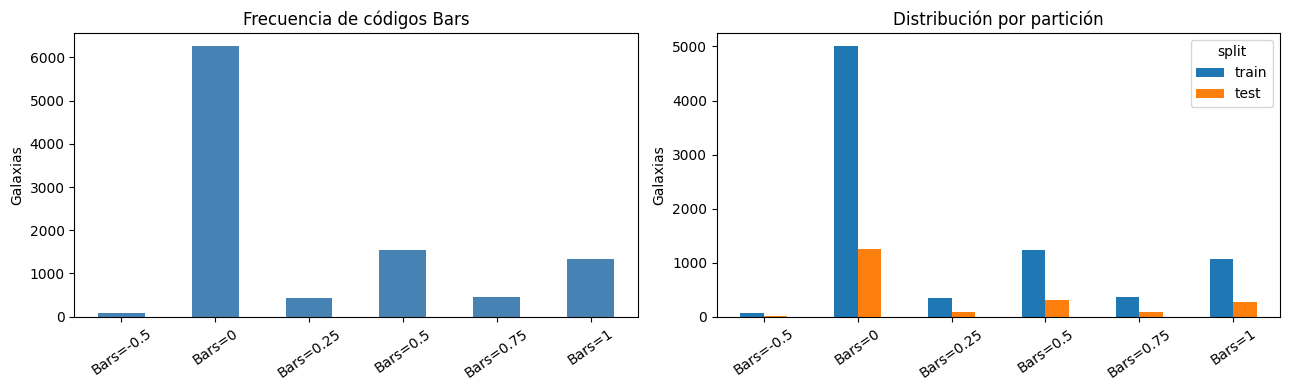

Accuracy de predecir la clase mayoritaria global: 61.76%
Esta accuracy no demuestra aprendizaje de códigos minoritarios.


In [4]:
# Etiquetas enteras aprendidas del train; no se impone un orden de intensidad.
train_mask = df['split'].eq('train')
test_mask = df['split'].eq('test')
CLASS_CODES = sorted(df.loc[train_mask, 'Bars'].unique())
if len(CLASS_CODES) < 2 or not set(df.loc[test_mask, 'Bars']).issubset(CLASS_CODES):
    raise ValueError('Train debe contener al menos dos clases y todas las clases presentes en test.')
CLASS_NAMES = [f'Bars={value:g}' for value in CLASS_CODES]
CODE_TO_ID = {code: i for i, code in enumerate(CLASS_CODES)}
LABELS = np.arange(len(CLASS_CODES))
K = len(LABELS)
df['target_id'] = df['Bars'].map(CODE_TO_ID).astype(int)
display(pd.DataFrame({'código_original': CLASS_CODES, 'etiqueta_modelo': LABELS,
                      'nombre_mostrado': CLASS_NAMES}))
class_counts = pd.crosstab(df['split'], df['target_id']).reindex(
    index=['train', 'test'], columns=LABELS, fill_value=0)
if (class_counts.loc['test'] < 1).any():
    raise ValueError('La prueba debe contener todas las clases para comparar métricas macro y ROC OvR.')
if class_counts.loc['train'].min() < CV_FOLDS:
    raise ValueError('Insuficientes ejemplos por clase para el número de folds configurado.')
class_counts.columns = CLASS_NAMES
display(class_counts)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
class_counts.sum().plot.bar(ax=axes[0], color='steelblue', rot=35)
axes[0].set(title='Frecuencia de códigos Bars', ylabel='Galaxias')
class_counts.T.plot.bar(ax=axes[1], rot=35)
axes[1].set(title='Distribución por partición', ylabel='Galaxias')
plt.tight_layout()
plt.show()
print(f'Accuracy de predecir la clase mayoritaria global: {class_counts.sum().max()/len(df):.2%}')
print('Esta accuracy no demuestra aprendizaje de códigos minoritarios.')

In [5]:
coverage = df.groupby('split').agg(
    galaxias=('name', 'size'), con_fits=('has_fits', 'sum'),
    con_caracteristicas_visuales=('has_image_features', 'sum'))
coverage['porcentaje_visual'] = 100 * coverage['con_caracteristicas_visuales'] / coverage['galaxias']
display(coverage)
coverage_by_class = df.groupby(['split', 'Bars']).agg(
    galaxias=('name', 'size'), con_imagen=('has_image_features', 'sum'))
coverage_by_class['porcentaje_visual'] = 100*coverage_by_class['con_imagen']/coverage_by_class['galaxias']
display(coverage_by_class)
visual_rate = df['has_image_features'].mean()
print(f'Cobertura visual declarada: {df["has_image_features"].sum():,}/{len(df):,} ({visual_rate:.2%})')
if image_columns_present:
    display(df[image_columns_present].isna().mean().mul(100).rename('% nulos por medida visual').to_frame())
print('La cobertura no mide representatividad ni exactitud de etiquetas; revisar su distribución por clase.')

,galaxias,con_fits,con_caracteristicas_visuales,porcentaje_visual
split,,,,
test,2026,10,10,0.493583
train,8100,40,40,0.493827


galaxias  con_imagen  porcentaje_visual
split Bars                                          
test  -0.50        19           2          10.526316
       0.00      1252           2           0.159744
       0.25        87           2           2.298851
       0.50       308           1           0.324675
       0.75        92           2           2.173913
       1.00       268           1           0.373134
train -0.50        74           7           9.459459
       0.00      5002           6           0.119952
       0.25       349           7           2.005731
       0.50      1234           7           0.567261
       0.75       364           6           1.648352
       1.00      1077           7           0.649954

Cobertura visual declarada: 50/10,126 (0.49%)


,% nulos por medida visual
g_mean,99.506222
g_std,99.506222
g_p95,99.506222
g_central_fraction,99.506222
g_asymmetry,99.506222
r_mean,99.506222
r_std,99.506222
r_p95,99.506222
r_central_fraction,99.506222
r_asymmetry,99.506222


La cobertura no mide representatividad ni exactitud de etiquetas; revisar su distribución por clase.


## 3. Características del baseline y prevención de fuga

Se calculan ocho atributos tabulares a partir de los valores originales: seno y coseno de RA y Dec, interacción `ra_sin × dec_cos`, raíz y `log(1+z)` y un indicador de ausencia de redshift. La transformación trigonométrica representa periodicidad de RA; los atributos de posición pueden capturar selección observacional y no son evidencia física de una barra. Las transformaciones de redshift son redundantes y se interpretan con cautela.

Los redshifts negativos (incluido el centinela -9999) se convierten a NaN. Se aplica raíz/logaritmo solo a valores válidos y se mantienen NaN hasta la imputación. Estas operaciones por fila no aprenden parámetros de otras galaxias. La **mediana se aprende dentro del Pipeline**, exclusivamente con train o con el entrenamiento de cada fold.

No se reutilizan `z_imputed`, bins, columnas escaladas, PCA, análisis factorial o selección supervisada del CSV. Así se evita heredar ajustes previos a la validación cruzada. Tampoco se utiliza el preprocesamiento del EDA, que imputó con la mediana del catálogo completo. Las características visuales crudas se reservan para el experimento complementario.

La inferencia se limita a galaxias del catálogo bajo una partición aleatoria estratificada existente. Separación por identificador no excluye duplicados astronómicos con otros nombres ni sesgos espaciales o de selección.

### Evidencia de cobertura en la ejecución real

Se unieron **10,126 identificadores únicos**, sin filas idénticas eliminadas. La partición contiene **8,100 galaxias de entrenamiento** y **2,026 de prueba**. El catálogo tiene **50 objetos con características visuales (0.49%)**: 40 en entrenamiento y 10 en prueba. Las columnas visuales presentan aproximadamente **99.51% de valores nulos** sobre el catálogo completo.

El baseline principal utiliza **ocho atributos tabulares** derivados de posición, redshift e indicador de ausencia; no utiliza imágenes imputadas para simular observaciones visuales. Se identificaron **29 redshifts no disponibles** bajo la regla de convertir todos los valores negativos a NaN, además de los nulos originales. El EDA previo contaba 28 ausencias al limpiar únicamente el centinela -9999. Ambas reglas de limpieza no son idénticas; sin inspeccionar el CSV real no se determina si la diferencia se debe a otros negativos, cambios del archivo o valores nulos adicionales. Comparar archivos y conteos antes de atribuir una causa.

La cobertura tampoco es uniforme entre códigos: en prueba, por ejemplo, `Bars=-0.5` tiene 2 imágenes de 19 objetos, mientras `Bars=0` tiene 2 de 1,252. Por tanto, los 50 FITS no representan automáticamente la distribución del catálogo. La cobertura limitada impide evaluar de forma concluyente el valor predictivo de las imágenes, pero no demuestra que explique por sí sola el bajo desempeño tabular.


In [6]:
z_clean = df['z'].mask(df['z'] < 0)
ra = np.deg2rad(df['objra'])
dec = np.deg2rad(df['objdec'])
X_all = pd.DataFrame({
    'ra_sin': np.sin(ra), 'ra_cos': np.cos(ra),
    'dec_sin': np.sin(dec), 'dec_cos': np.cos(dec),
    'ra_dec_interaction': np.sin(ra)*np.cos(dec),
    'z_sqrt': np.sqrt(z_clean), 'z_log1p': np.log1p(z_clean),
    'z_missing': z_clean.isna().astype(int)
}, index=df.index)
FEATURE_COLS = X_all.columns.tolist()
X_train = X_all.loc[train_mask].copy()
X_test = X_all.loc[test_mask].copy()
y_train = df.loc[train_mask, 'target_id'].to_numpy()
y_test = df.loc[test_mask, 'target_id'].to_numpy()
if X_train.isna().all().any():
    raise ValueError('Hay una característica totalmente vacía en entrenamiento; revisar datos antes de imputar.')
print(f'Train: {X_train.shape} | test: {X_test.shape} | clases: {K}')
print(f'Redshifts no disponibles: {z_clean.isna().sum()}')
display(X_all.isna().sum().rename('nulos antes de imputar').to_frame())

# labels explícitas mantienen la misma definición macro durante toda la evaluación.
macro_f1_scorer = make_scorer(f1_score, labels=LABELS, average='macro', zero_division=0)
def make_rf():
    return Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('model', RandomForestClassifier(**RF_CONFIG))])

def evaluate(estimator, X, y):
    pred = estimator.predict(X)
    prob = estimator.predict_proba(X)
    if list(estimator.classes_) != list(LABELS):
        raise ValueError('El modelo no contiene todas las clases en el orden esperado.')
    binary_targets = (np.asarray(y)[:, None] == LABELS[None, :]).astype(int)
    per_class_ap = np.array([average_precision_score(binary_targets[:, i], prob[:, i]) for i in LABELS])
    roc = (roc_auc_score(y, prob[:, 1]) if K == 2 else
           roc_auc_score(y, prob, labels=LABELS, multi_class='ovr', average='macro'))
    metrics = {
        'F1-macro': f1_score(y, pred, labels=LABELS, average='macro', zero_division=0),
        'Precision-macro': precision_score(y, pred, labels=LABELS, average='macro', zero_division=0),
        'Recall-macro': recall_score(y, pred, labels=LABELS, average='macro', zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y, pred),
        'Accuracy': accuracy_score(y, pred), 'ROC-AUC OvR macro': roc,
        'AP macro OvR': per_class_ap.mean()
    }
    return metrics, pred, prob

Train: (8100, 8) | test: (2026, 8) | clases: 6
Redshifts no disponibles: 29


,nulos antes de imputar
ra_sin,0
ra_cos,0
dec_sin,0
dec_cos,0
ra_dec_interaction,0
z_sqrt,29
z_log1p,29
z_missing,0


## 4. Algoritmo y comparadores — justificación

| Modelo | Papel | Justificación y límite |
|---|---|---|
| Dummy mayoritario | Referencia sin usar relaciones con los atributos | Expone la accuracy obtenible ignorando las clases minoritarias. |
| Dummy estratificado | Referencia aleatoria basada en frecuencias de train | Su resultado depende de la semilla; una ejecución no constituye un piso universal ni una prueba estadística. |
| Random Forest | Baseline principal tabular | Representa relaciones no lineales e interacciones, no exige escalado y permite ponderar clases. Su elección no demuestra superioridad sobre todas las alternativas. |
| Regresión logística regularizada | Alternativa simple para un experimento posterior | Es válida con preprocesamiento apropiado. La correlación no obliga a descartarla; no se declara que rinda peor sin ejecutarla. |
| Modelo de imagen | Desarrollo futuro | Requiere cobertura y representación visual adecuadas; no se anticipan puntuaciones. |

Random Forest se elige por la estructura numérica, el volumen tabular, las interacciones y el desbalance. El ensamble puede aprender señales de selección observacional; su importancia no es causal. Se fijan **300 árboles**, profundidad máxima **10**, mínimo **5** muestras por hoja y pesos `balanced`. Son restricciones iniciales de complejidad, no valores óptimos demostrados. No se realiza ajuste contra prueba.

La importancia de atributos se estudia por permutación individual y por grupos correlacionados; es una inspección post hoc del modelo, no selección automática ni extracción de variables. No se agrega escalado porque no es necesario para el Random Forest.

## 5. Métricas alineadas con el problema

**Principal: F1-macro.** Se calcula F1 de cada código y se promedian con igual peso. Permite que los códigos poco frecuentes contribuyan al resultado; `Bars` no se trata como escala continua, por lo que no se usan MAE, RMSE o R². Macro-F1 no significa porcentaje de barras detectadas físicamente.

**Complementarias:** precisión, recall y F1 por código; accuracy; balanced accuracy (equivale a recall macro cuando están todas las clases); ROC-AUC One-vs-Rest macro y AP One-vs-Rest macro. Para cada código se compara frente al resto y se promedia con igual peso. AP integra por incrementos de recall y no es necesariamente un área trapezoidal. La prevalencia de cada código es una referencia para su curva PR; la media de esas prevalencias es `1/K`, no se usa la prevalencia binaria de anillos.

Se reportan métricas por clase para evitar que un promedio oculte fallas. Antes de un uso físico del modelo debe confirmarse el significado de los códigos y el costo de confundirlos. Las puntuaciones describen la partición actual, sin demostrar significancia estadística.

In [7]:
dummy_rows = []
for strategy in ['most_frequent', 'stratified']:
    dummy = Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                      ('model', DummyClassifier(strategy=strategy, random_state=RANDOM_STATE))])
    dummy.fit(X_train, y_train)
    metrics, pred, _ = evaluate(dummy, X_test, y_test)
    dummy_rows.append({'Modelo': f'Dummy {strategy}', **metrics})
    print(f'\nDummy {strategy}')
    print(classification_report(y_test, pred, labels=LABELS, target_names=CLASS_NAMES, zero_division=0))
display(pd.DataFrame(dummy_rows).round(4))

rf = make_rf()
rf.fit(X_train, y_train)
train_metrics, y_pred_train, _ = evaluate(rf, X_train, y_train)
test_metrics, y_pred_test, y_prob_test = evaluate(rf, X_test, y_test)
comparison = pd.DataFrame(dummy_rows + [{'Modelo': 'Random Forest tabular', **test_metrics}])
display(comparison.round(4))
print(classification_report(y_test, y_pred_test, labels=LABELS, target_names=CLASS_NAMES, zero_division=0))
report = pd.DataFrame(classification_report(y_test, y_pred_test, labels=LABELS,
                     target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T
class_report = report.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score', 'support']]


Dummy most_frequent
              precision    recall  f1-score   support

   Bars=-0.5       0.00      0.00      0.00        19
      Bars=0       0.62      1.00      0.76      1252
   Bars=0.25       0.00      0.00      0.00        87
    Bars=0.5       0.00      0.00      0.00       308
   Bars=0.75       0.00      0.00      0.00        92
      Bars=1       0.00      0.00      0.00       268

    accuracy                           0.62      2026
   macro avg       0.10      0.17      0.13      2026
weighted avg       0.38      0.62      0.47      2026


Dummy stratified
              precision    recall  f1-score   support

   Bars=-0.5       0.00      0.00      0.00        19
      Bars=0       0.63      0.63      0.63      1252
   Bars=0.25       0.01      0.01      0.01        87
    Bars=0.5       0.15      0.16      0.15       308
   Bars=0.75       0.07      0.07      0.07        92
      Bars=1       0.14      0.14      0.14       268

    accuracy                          

,Modelo,F1-macro,Precision-macro,Recall-macro,Balanced accuracy,Accuracy,ROC-AUC OvR macro,AP macro OvR
0,Dummy most_frequent,0.1273,0.1030,0.1667,0.1667,0.6180,0.5000,0.1667
1,Dummy stratified,0.1668,0.1672,0.1665,0.1665,0.4339,0.5017,0.1684


,Modelo,F1-macro,Precision-macro,Recall-macro,Balanced accuracy,Accuracy,ROC-AUC OvR macro,AP macro OvR
0,Dummy most_frequent,0.1273,0.1030,0.1667,0.1667,0.6180,0.5000,0.1667
1,Dummy stratified,0.1668,0.1672,0.1665,0.1665,0.4339,0.5017,0.1684
2,Random Forest tabular,0.1711,0.1934,0.1867,0.1867,0.3031,0.5562,0.1911


              precision    recall  f1-score   support

   Bars=-0.5       0.00      0.00      0.00        19
      Bars=0       0.72      0.35      0.47      1252
   Bars=0.25       0.06      0.09      0.08        87
    Bars=0.5       0.17      0.27      0.21       308
   Bars=0.75       0.06      0.15      0.09        92
      Bars=1       0.14      0.26      0.18       268

    accuracy                           0.30      2026
   macro avg       0.19      0.19      0.17      2026
weighted avg       0.50      0.30      0.36      2026



## 6. Sub/sobreajuste: entrenamiento, prueba y validación

Se comparan varias métricas en entrenamiento y prueba. Una brecha positiva grande es compatible con sobreajuste, pero no prueba una causa específica. Se usa 0.10 de diferencia en F1-macro como alerta heurística. Una brecha pequeña no garantiza calidad si ambos valores son bajos; desempeño bajo por sí solo no prueba ausencia de información.

La curva usa el mismo pipeline y configuración del baseline con folds estratificados y mezcla reproducible. La imputación se ajusta dentro de cada fold. Las bandas son desviación estándar entre folds, no intervalos de confianza. La curva explora el rango observado y no permite afirmar que agregar datos nunca ayudará.

### Interpretación de esta ejecución

| Métrica | Entrenamiento | Prueba | Brecha |
|---|---:|---:|---:|
| F1-macro | 0.4784 | 0.1711 | 0.3073 |
| Recall-macro / balanced accuracy | 0.7217 | 0.1867 | 0.5350 |
| ROC-AUC OvR macro | 0.8968 | 0.5562 | 0.3406 |
| AP macro OvR | 0.6652 | 0.1911 | 0.4740 |

Las brechas coincidentes entre varias métricas son compatibles con **sobreajuste y generalización limitada**. El entrenamiento es claramente superior a prueba, aunque su F1-macro tampoco alcanza la meta de trabajo de 0.50; no se atribuye una causa única ni se diagnostica exclusivamente subajuste por tener un resultado bajo.

En la curva, F1-macro de entrenamiento desciende aproximadamente de **0.70 a 0.52**, mientras validación oscila alrededor de **0.18–0.19**. Al mayor tamaño, validación es **0.1874 ± 0.0092** y la brecha entrenamiento-validación es **0.3298**. La variación de validación entre los extremos es **−0.0046**: no se aprecia una mejora sostenida dentro del rango evaluado. Esto no permite extrapolar el efecto de recuperar imágenes o de incorporar nuevas variables visuales, pues la curva usa únicamente el escenario tabular.

Validación supera prueba aproximadamente en **0.0163**, diferencia que no constituye una prueba de cambio de distribución ni de significancia. La dispersión entre folds no es un intervalo de confianza de prueba. Antes de aumentar complejidad, corresponde revisar la definición del objetivo, las fuentes de información y el control de complejidad dentro de entrenamiento.


,Entrenamiento,Prueba,Brecha train-test
F1-macro,0.4784,0.1711,0.3073
Precision-macro,0.4348,0.1934,0.2414
Recall-macro,0.7217,0.1867,0.5350
Balanced accuracy,0.7217,0.1867,0.5350
Accuracy,0.5178,0.3031,0.2147
ROC-AUC OvR macro,0.8968,0.5562,0.3406
AP macro OvR,0.6652,0.1911,0.4740


Indicio de sobreajuste: brecha de F1-macro mayor que 0.10.


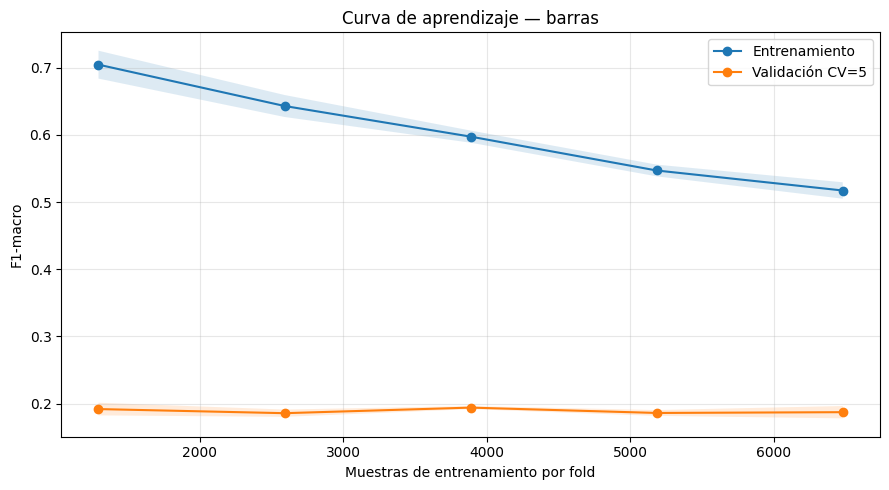

Validación al mayor tamaño: 0.1874 ± 0.0092
Brecha train-validación al mayor tamaño: 0.3298
Variación de validación entre extremos observados: -0.0046
El mayor tamaño es el entrenamiento de cada fold, no todo el train global.


In [8]:
fit_table = pd.DataFrame([train_metrics, test_metrics], index=['Entrenamiento', 'Prueba']).T
fit_table['Brecha train-test'] = fit_table['Entrenamiento'] - fit_table['Prueba']
display(fit_table.round(4))
train_f1 = train_metrics['F1-macro']
test_f1 = test_metrics['F1-macro']
gap = train_f1 - test_f1
best_dummy_f1 = max(row['F1-macro'] for row in dummy_rows)
if gap > GAP_ALERT:
    diagnosis = 'Indicio de sobreajuste: brecha de F1-macro mayor que 0.10.'
elif test_f1 <= best_dummy_f1:
    diagnosis = 'Sin mejora observada en F1 frente al mejor Dummy: investigar señal y ajuste; no basta para afirmar subajuste.'
elif gap < -0.05:
    diagnosis = 'Prueba supera entrenamiento: revisar composición y variabilidad de las particiones.'
else:
    diagnosis = 'Sin brecha grande bajo la alerta utilizada; revisar nivel absoluto y validación.'
print(diagnosis)

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
curve_model = clone(rf).set_params(model__n_jobs=1)
train_sizes, train_scores, val_scores = learning_curve(
    curve_model, X_train, y_train, train_sizes=TRAIN_FRACTIONS,
    scoring=macro_f1_scorer, cv=cv, shuffle=True,
    random_state=RANDOM_STATE, n_jobs=-1, error_score='raise')
tm, ts = train_scores.mean(axis=1), train_scores.std(axis=1)
vm, vs = val_scores.mean(axis=1), val_scores.std(axis=1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, tm, 'o-', label='Entrenamiento')
ax.fill_between(train_sizes, tm-ts, tm+ts, alpha=0.15)
ax.plot(train_sizes, vm, 'o-', label=f'Validación CV={CV_FOLDS}')
ax.fill_between(train_sizes, vm-vs, vm+vs, alpha=0.15)
ax.set(xlabel='Muestras de entrenamiento por fold', ylabel='F1-macro', title='Curva de aprendizaje — barras')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Validación al mayor tamaño: {vm[-1]:.4f} ± {vs[-1]:.4f}')
print(f'Brecha train-validación al mayor tamaño: {tm[-1]-vm[-1]:.4f}')
print(f'Variación de validación entre extremos observados: {vm[-1]-vm[0]:+.4f}')
print('El mayor tamaño es el entrenamiento de cada fold, no todo el train global.')

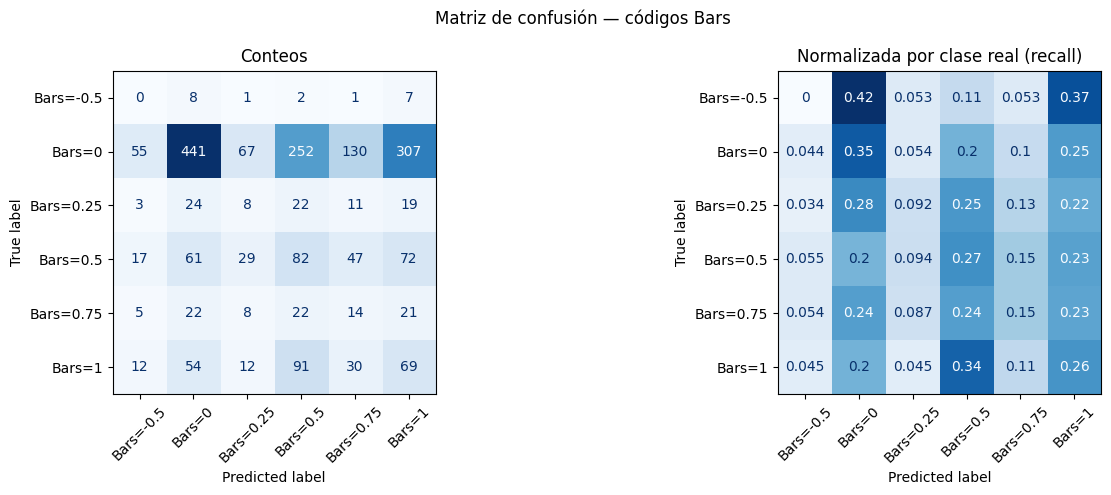

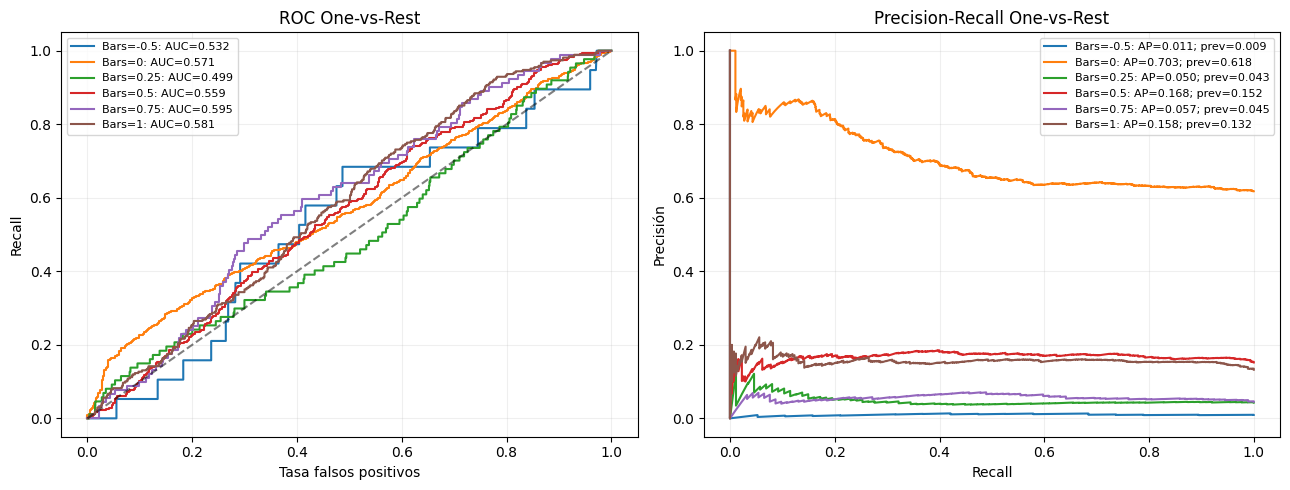

Interpretación de PR: comparar el AP de cada código con su prevalencia, mostrada en la leyenda.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, normalize, title in zip(axes, [None, 'true'], ['Conteos', 'Normalizada por clase real (recall)']):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=LABELS,
        display_labels=CLASS_NAMES, normalize=normalize, cmap='Blues',
        ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(title)
plt.suptitle('Matriz de confusión — códigos Bars')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i, name in enumerate(CLASS_NAMES):
    binary_y = (y_test == i).astype(int)
    fpr, tpr, _ = roc_curve(binary_y, y_prob_test[:, i])
    precision, recall, _ = precision_recall_curve(binary_y, y_prob_test[:, i])
    auc_i = roc_auc_score(binary_y, y_prob_test[:, i])
    ap_i = average_precision_score(binary_y, y_prob_test[:, i])
    axes[0].plot(fpr, tpr, label=f'{name}: AUC={auc_i:.3f}')
    axes[1].plot(recall, precision, label=f'{name}: AP={ap_i:.3f}; prev={binary_y.mean():.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set(xlabel='Tasa falsos positivos', ylabel='Recall', title='ROC One-vs-Rest')
axes[1].set(xlabel='Recall', ylabel='Precisión', title='Precision-Recall One-vs-Rest')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Interpretación de PR: comparar el AP de cada código con su prevalencia, mostrada en la leyenda.')

## 7. Relevancia de características con visualización e interpretación

Permutation importance mide la caída en F1-macro al permutar un atributo en prueba, manteniendo el modelo fijo. No implica causalidad ni utilidad intrínseca; su valor depende del modelo entrenado. Correlaciones entre originales y transformaciones pueden ocultar importancia individual.

Se agrega una permutación por grupos para mover conjuntamente atributos de posición, redshift y ausencia. Se utiliza la misma permutación de filas dentro de cada grupo para conservar sus dependencias internas. El efecto del grupo no es la suma de importancias individuales ni elimina toda dependencia entre grupos. Las barras de error representan dispersión entre permutaciones, no intervalos de confianza poblacionales.

Este análisis describe el modelo final. **No se elimina ni selecciona ninguna variable con el ranking de prueba.** Si motiva modificaciones, evaluarlas dentro de entrenamiento y reservar una evaluación independiente.

### Interpretación del ranking observado

| Atributo o grupo | Caída media de F1-macro | Dispersión entre permutaciones | Lectura |
|---|---:|---:|---|
| `z_missing` individual | 0.000000 | 0.000000 | La permutación no cambia la puntuación observada. Encabeza el ranking por ser cero frente a medias negativas, no por mostrar una contribución positiva. |
| `z_sqrt` individual | −0.002503 | 0.004328 | Permutarlo mejora ligeramente el promedio en esta prueba; no basta para eliminarlo. |
| `z_log1p` individual | −0.005658 | 0.003692 | No muestra una contribución individual positiva bajo esta inspección del modelo. |
| Redshift transformado, grupo | 0.013796 | 0.008728 | Permutar conjuntamente raíz y logaritmo produce una caída media positiva; es compatible con información compartida que la permutación individual no refleja. |
| Posición e interacción, grupo | 0.002452 | 0.005919 | La dispersión supera la media: efecto pequeño y poco estable bajo las permutaciones realizadas. |

Las siete variables individuales distintas de `z_missing` presentan medias negativas. El método **no identifica una importancia individual positiva** en esta ejecución. Esto describe cómo responde este Random Forest a la perturbación de sus entradas, no demuestra que todas las variables sean intrínsecamente inútiles.

La raíz y el logaritmo del mismo redshift contienen información redundante. El contraste entre sus importancias individuales y la permutación conjunta justifica examinar atributos por grupos; no implica sumar importancias ni demuestra una relación causal entre redshift y barras. La caída conjunta de **0.013796** equivale aproximadamente a **1.38 puntos porcentuales de F1-macro**, con dispersión considerable y sin prueba de significancia estadística.

No se eliminan características con este ranking de prueba. Una comparación de subconjuntos, regularización o modelos alternativos debe seleccionarse dentro de entrenamiento; si las observaciones de prueba motivan cambios, se necesita una evaluación independiente para respaldar mejoras generales.


,feature,importance_mean,importance_std
7,z_missing,0.000000,0.000000
5,z_sqrt,-0.002503,0.004328
1,ra_cos,-0.004324,0.003791
6,z_log1p,-0.005658,0.003692
0,ra_sin,-0.006187,0.005363
4,ra_dec_interaction,-0.006821,0.004327
2,dec_sin,-0.007661,0.003482
3,dec_cos,-0.009263,0.004621


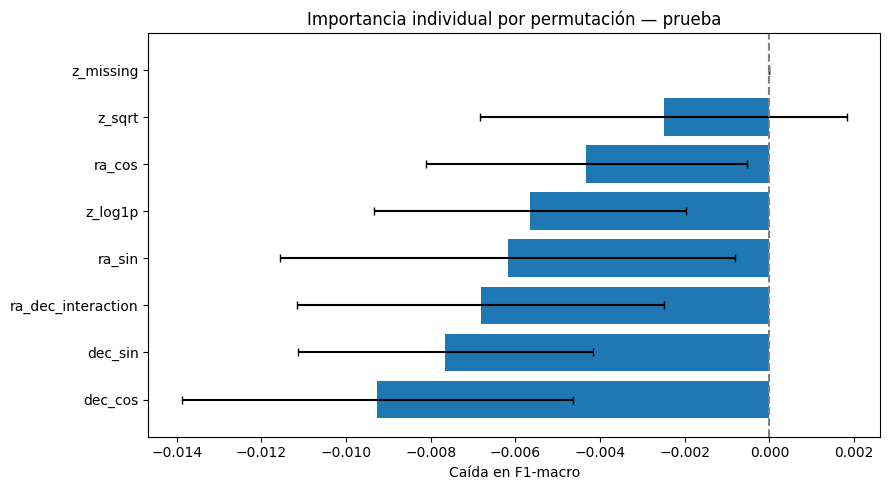

,grupo,caida_media,dispersion
1,Redshift transformado,0.013796,0.008728
0,Posición e interacción,0.002452,0.005919
2,Ausencia de redshift,0.000000,0.000000


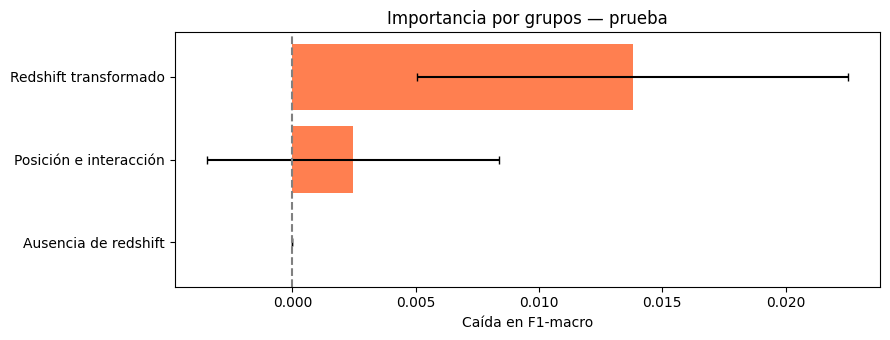

Mayor media individual: z_missing = 0.00000 ± 0.00000
La primera media no es positiva o su dispersión es al menos tan grande: ranking individual poco concluyente.
Medias negativas: la permutación mejoró el promedio observado; no es prueba suficiente para eliminar atributos.
Posición/redshift pueden describir selección del catálogo; su importancia no demuestra detección visual de barras.


In [10]:
perm = permutation_importance(rf, X_test, y_test, scoring=macro_f1_scorer,
    n_repeats=PERM_REPEATS, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({'feature': FEATURE_COLS,
    'importance_mean': perm.importances_mean, 'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)
display(perm_df)
fig, ax = plt.subplots(figsize=(9, 5))
ordered = perm_df.iloc[::-1]
ax.barh(ordered['feature'], ordered['importance_mean'], xerr=ordered['importance_std'], capsize=3)
ax.axvline(0, color='gray', linestyle='--')
ax.set(xlabel='Caída en F1-macro', title='Importancia individual por permutación — prueba')
plt.tight_layout()
plt.show()

FEATURE_GROUPS = {
    'Posición e interacción': ['ra_sin', 'ra_cos', 'dec_sin', 'dec_cos', 'ra_dec_interaction'],
    'Redshift transformado': ['z_sqrt', 'z_log1p'],
    'Ausencia de redshift': ['z_missing']
}
rng = np.random.default_rng(RANDOM_STATE)
group_rows = []
for name, columns in FEATURE_GROUPS.items():
    drops = []
    for _ in range(PERM_REPEATS):
        shuffled = X_test.copy()
        order = rng.permutation(len(X_test))
        shuffled.loc[:, columns] = X_test.iloc[order][columns].to_numpy()
        drops.append(test_f1 - macro_f1_scorer(rf, shuffled, y_test))
    group_rows.append({'grupo': name, 'caida_media': np.mean(drops), 'dispersion': np.std(drops)})
group_df = pd.DataFrame(group_rows).sort_values('caida_media', ascending=False)
display(group_df)
fig, ax = plt.subplots(figsize=(9, 3.5))
ordered = group_df.iloc[::-1]
ax.barh(ordered['grupo'], ordered['caida_media'], xerr=ordered['dispersion'], capsize=3, color='coral')
ax.axvline(0, color='gray', linestyle='--')
ax.set(xlabel='Caída en F1-macro', title='Importancia por grupos — prueba')
plt.tight_layout()
plt.show()
top = perm_df.iloc[0]
print(f'Mayor media individual: {top["feature"]} = {top["importance_mean"]:.5f} ± {top["importance_std"]:.5f}')
if top['importance_mean'] <= 0 or top['importance_mean'] <= top['importance_std']:
    print('La primera media no es positiva o su dispersión es al menos tan grande: ranking individual poco concluyente.')
print('Medias negativas: la permutación mejoró el promedio observado; no es prueba suficiente para eliminar atributos.')
print('Posición/redshift pueden describir selección del catálogo; su importancia no demuestra detección visual de barras.')

## 8. Experimento complementario tabular + imagen

Solo se consideran filas con `has_image_features == 1` y las 15 medidas visuales crudas completas. No se rellenan imágenes ausentes del catálogo principal para simular mediciones visuales. Se evalúan dos modelos sobre **exactamente los mismos objetos y etiquetas** del subconjunto visual: tabular y tabular + imagen, con la configuración fija de Random Forest y el `split` existente.

Para ejecutar, se exigen al menos cinco ejemplos de cada clase en entrenamiento, dos en prueba y 30 observaciones de entrenamiento en total. Son condiciones prácticas mínimas, no una garantía de validez estadística. Si no se cumplen o faltan columnas, se informa y se omite el experimento sin detener el baseline principal.

Con solo 50 FITS en la ingeniería compartida es probable que se omita. Las conclusiones sobre el valor de las imágenes no deben basarse en una muestra tan pequeña o no representativa. Tampoco se compara directamente el F1 de este subconjunto con el del catálogo completo como si midieran el efecto de agregar imágenes.

### Resultado del experimento visual

La ejecución **omitió correctamente** la comparación tabular frente a tabular + imagen: en prueba, los códigos `Bars=0.5` y `Bars=1` cuentan con **una sola imagen por código**, por debajo del mínimo práctico configurado de dos. El resto tiene dos por código. Aunque entrenamiento tiene entre seis y siete por clase, eso no resuelve la escasez de prueba.

No se reporta una puntuación visual ni se concluye que agregar imágenes mejoraría o empeoraría el modelo. Se conserva el experimento como un protocolo para ejecutar cuando exista cobertura suficiente, sin reducir los requisitos después de observar los datos.


In [11]:
image_comparison = None
image_status = 'Desactivado en configuración.'
if RUN_IMAGE_EXPERIMENT:
    missing_visual = [col for col in IMAGE_FEATURES if col not in df]
    if missing_visual:
        image_status = f'Omitido: faltan columnas visuales: {missing_visual}'
    else:
        usable_img = df['has_image_features'].eq(1) & df[IMAGE_FEATURES].notna().all(axis=1)
        mask_img_train = train_mask & usable_img
        mask_img_test = test_mask & usable_img
        n_img_train = df.loc[mask_img_train, 'target_id'].value_counts().reindex(LABELS, fill_value=0)
        n_img_test = df.loc[mask_img_test, 'target_id'].value_counts().reindex(LABELS, fill_value=0)
        display(pd.DataFrame({'clase': CLASS_NAMES, 'train_visual': n_img_train.to_numpy(),
                              'test_visual': n_img_test.to_numpy()}))
        if n_img_train.min() < 5 or n_img_test.min() < 2 or mask_img_train.sum() < 30:
            image_status = 'Omitido por cobertura insuficiente por clase; no se estima el efecto predictivo de imágenes.'
        else:
            X_combined = pd.concat([X_all, df[IMAGE_FEATURES]], axis=1)
            image_rows_metrics = []
            for name, X in [('Tabular en subconjunto visual', X_all),
                            ('Tabular + imagen en mismo subconjunto', X_combined)]:
                image_model = make_rf()
                image_model.fit(X.loc[mask_img_train], df.loc[mask_img_train, 'target_id'].to_numpy())
                metrics, _, _ = evaluate(image_model, X.loc[mask_img_test],
                                         df.loc[mask_img_test, 'target_id'].to_numpy())
                image_rows_metrics.append({'Modelo': name, **metrics})
            image_comparison = pd.DataFrame(image_rows_metrics)
            display(image_comparison.round(4))
            delta_image_f1 = image_comparison.iloc[1]['F1-macro'] - image_comparison.iloc[0]['F1-macro']
            image_status = f'Exploratorio ejecutado: diferencia pareada de F1-macro al agregar imagen = {delta_image_f1:+.4f}.'
            print('La diferencia observada no demuestra significancia ni se extrapola al catálogo completo.')
print(image_status)

,clase,train_visual,test_visual
0,Bars=-0.5,7,2
1,Bars=0,6,2
2,Bars=0.25,7,2
3,Bars=0.5,7,1
4,Bars=0.75,6,2
5,Bars=1,7,1


Omitido por cobertura insuficiente por clase; no se estima el efecto predictivo de imágenes.


## 9. Desempeño mínimo: definición, justificación y verificación

La rúbrica solicita establecer un desempeño mínimo y **verificar si** el baseline alcanza un nivel aceptable; no se declara cumplimiento cuando el resultado está por debajo. No se dispone de un desempeño histórico comparable del problema multiclase de barras: el baseline binario de anillos no lo reemplaza.

Antes de ejecutar se fijan estas metas de trabajo en la configuración:

| Criterio | Meta | Justificación y límite |
|---|---:|---|
| F1-macro | ≥ 0.50 | Exige una calidad media por categoría superior a una clasificación trivial en este problema de seis códigos. La referencia aleatoria debe medirse con Dummy; no es 0.50 por tratarse de clasificación. El valor 0.50 es una decisión prospectiva de trabajo, no una garantía de buen desempeño para cada clase. |
| ROC-AUC OvR macro | ≥ 0.80 | Exige discriminación por código frente al resto además del resultado de clasificación. El valor 0.80 es una meta del proyecto, no un estándar astronómico. |
| Regla conjunta | Ambas metas | Evita aceptar el modelo solo por mejorar frente a Dummy o por tener un ranking favorable sin F1 suficiente. |

Estos objetivos son provisionales para utilidad científica: requieren validación del diccionario de etiquetas, costos de error y representatividad antes de un uso real. Su verificación académica se realiza igualmente y se informa tanto cumplimiento como incumplimiento. No se reducen tras observar resultados ni se importa el F1 objetivo de anillos como si fuera el mismo problema.

La comparación con Dummy se presenta por separado y no sustituye la regla conjunta. La ausencia de intervalos de confianza impide afirmar que una diferencia pequeña o un cruce marginal del umbral sea concluyente.

### Verificación y lectura de los resultados reales

| Criterio | Meta fijada | Resultado en prueba | Diferencia respecto a la meta | Verificación |
|---|---:|---:|---:|---|
| F1-macro | 0.50 | 0.1711 | −0.3289 | No cumple |
| ROC-AUC OvR macro | 0.80 | 0.5562 | −0.2438 | No cumple |

**El baseline no alcanza el mínimo de trabajo.** F1-macro supera al Dummy estratificado de **0.1668** únicamente en **0.0043** (aproximadamente 0.43 puntos porcentuales). ROC-AUC OvR macro es **0.5562** frente a **0.5017** del mismo Dummy, y AP macro OvR es **0.1911** frente a **0.1684**. Estas son diferencias descriptivas; no acreditan una mejora concluyente sin evaluar incertidumbre.

La accuracy del modelo es **0.3031**, inferior al **0.6180** del Dummy mayoritario. Esto no convierte accuracy en el criterio principal: la regla mayoritaria solo predice `Bars=0` y no recupera los otros cinco códigos. El desempeño de ambos modelos sigue siendo limitado bajo el objetivo de clasificar todas las categorías.

Se cumplen las tareas de establecer una meta, medir el rendimiento y verificar el estado actual del problema, sin afirmar que la meta se haya alcanzado. Se mantienen las metas prospectivas y se documenta el incumplimiento; no se modifican para declarar aceptación.


In [12]:
minimum_table = pd.DataFrame([
    {'Criterio': 'F1-macro', 'Meta': MIN_F1_MACRO, 'Observado': test_metrics['F1-macro']},
    {'Criterio': 'ROC-AUC OvR macro', 'Meta': MIN_ROC_OVR, 'Observado': test_metrics['ROC-AUC OvR macro']}
])
minimum_table['Diferencia observado-meta'] = minimum_table['Observado'] - minimum_table['Meta']
minimum_table['Resultado'] = np.where(minimum_table['Observado'] >= minimum_table['Meta'], 'CUMPLE', 'NO CUMPLE')
minimum_ok = bool((minimum_table['Resultado'] == 'CUMPLE').all())
display(minimum_table.round(4))
print('Regla conjunta:', 'CUMPLE AMBAS METAS DE TRABAJO' if minimum_ok else 'NO ALCANZA AMBAS METAS DE TRABAJO')
print(f'Mejora F1-macro frente al mejor Dummy: {test_f1-best_dummy_f1:+.4f}')
print('Las metas de trabajo no certifican utilidad científica ni resuelven el significado pendiente de los códigos.')

,Criterio,Meta,Observado,Diferencia observado-meta,Resultado
0,F1-macro,0.5,0.1711,-0.3289,NO CUMPLE
1,ROC-AUC OvR macro,0.8,0.5562,-0.2438,NO CUMPLE


Regla conjunta: NO ALCANZA AMBAS METAS DE TRABAJO
Mejora F1-macro frente al mejor Dummy: +0.0043
Las metas de trabajo no certifican utilidad científica ni resuelven el significado pendiente de los códigos.


## 10. Conclusiones calculadas y relación con la rúbrica

El resumen siguiente utiliza las variables de la ejecución, no cifras copiadas de anillos. Debe leerse junto con las tablas, matrices y gráficas. Los promedios por código no sustituyen la revisión de clases minoritarias ni la validación semántica del catálogo.

### Conclusión analítica — Equipo 38

El experimento ejecutado establece una referencia reproducible para predecir **seis códigos categóricos `Bars`** a partir de ocho atributos tabulares. Random Forest obtiene **F1-macro de 0.1711**, **ROC-AUC OvR macro de 0.5562** y **AP macro OvR de 0.1911**. La mejora de F1 frente al Dummy estratificado es mínima (**+0.0043**) y no se demuestra significancia estadística. No se dispone de evidencia suficiente para presentar el modelo como un clasificador útil de las seis categorías o como un detector visual de barras.

El modelo muestra sobreajuste: entrenamiento alcanza F1-macro **0.4784**, con brecha de **0.3073** frente a prueba. La validación cruzada y su curva refuerzan el diagnóstico; agregar muestras dentro del rango tabular evaluado no produce una mejora sostenida de validación.

La matriz de confusión contiene **614 predicciones correctas de 2,026**. El mejor recall corresponde a `Bars=0`, con **441/1,252 = 35.22%**; el código `Bars=-0.5` no se recupera (**0/19**). También se observan confusiones entre categorías, por ejemplo **91 de 268** objetos `Bars=1` se predicen como `Bars=0.5`. Esto describe códigos del catálogo; sin su diccionario no se interpreta como confusión entre intensidades físicas específicas.

La inspección no muestra contribuciones individuales positivas. El grupo de transformaciones de redshift presenta una caída media positiva de **0.0138**, compatible con dependencia compartida, pero no con causalidad morfológica demostrada. La cobertura visual de **0.49%** y la escasez por clase obligan a omitir la comparación visual. Por tanto, este resultado no prueba la utilidad o inutilidad de características de imagen.

**Ambas metas de trabajo se incumplen.** El valor del avance es cuantificar la referencia y sus limitaciones, verificar el nivel aceptable y orientar los siguientes experimentos con evidencia.

### Pendientes científicos y siguiente experimento

1. Confirmar el diccionario de `Bars`, particularmente `-0.5`, con el catálogo original. No asignar automáticamente presencia, ausencia, intensidad o descarte a códigos sin respaldo documental. Si cambia la definición del objetivo, documentar un nuevo protocolo antes de evaluarlo.
2. Reconciliar las 29 ausencias actuales de redshift con las 28 del EDA previo, verificando versiones del archivo, nulos y negativos, y justificar la política de limpieza. Mantener imputación dentro del pipeline y registrar los archivos y versiones utilizados.
3. Revisar disponibilidad, extracción y representatividad de FITS por código. Recuperar mediciones visuales permitiría evaluar otra fuente de información, pero no garantiza mayor desempeño.
4. Dentro de entrenamiento, evaluar un modelo lineal regularizado o restricciones adicionales de Random Forest y comparar grupos de atributos. Seleccionar cambios por validación cruzada, sin optimizar sobre esta prueba ya inspeccionada.
5. Reservar una evaluación independiente para sustentar generalización si se modifican objetivos, variables o parámetros a partir de estos hallazgos.

La nota del Equipo 38, las referencias metodológicas y los resultados originales se conservan. Esta actualización modifica la interpretación y el estado de ejecución; no cambia etiquetas, particiones, hiperparámetros, metas ni predicciones.


In [13]:
worst_class = class_report['recall'].idxmin()
best_class = class_report['recall'].idxmax()
top_group = group_df.iloc[0]
print('CONCLUSIÓN — BASELINE DE BARRAS, EQUIPO 38')
print(f'Problema: {K} códigos categóricos Bars: {CLASS_CODES}.')
print(f'Datos: {len(df):,} galaxias; train={len(y_train):,}, test={len(y_test):,}; {len(FEATURE_COLS)} atributos tabulares.')
print(f'F1-macro train/test: {train_f1:.4f}/{test_f1:.4f}; brecha={gap:.4f}.')
print(diagnosis)
print(f'Validación al mayor tamaño: {vm[-1]:.4f} ± {vs[-1]:.4f}; brecha train-val={tm[-1]-vm[-1]:.4f}.')
print(f'ROC-AUC OvR macro test={test_metrics["ROC-AUC OvR macro"]:.4f}; AP macro OvR={test_metrics["AP macro OvR"]:.4f}.')
print(f'Diferencia F1-macro frente al mejor Dummy: {test_f1-best_dummy_f1:+.4f}; no se afirma significancia estadística.')
print(f'Mayor recall: {best_class}={class_report.loc[best_class, "recall"]:.3f}; menor recall: {worst_class}={class_report.loc[worst_class, "recall"]:.3f}.')
print(f'Primera importancia individual: {top["feature"]} ({top["importance_mean"]:.5f} ± {top["importance_std"]:.5f}).')
print(f'Primera importancia por grupo: {top_group["grupo"]} ({top_group["caida_media"]:.5f} ± {top_group["dispersion"]:.5f}).')
print('Las importancias describen dependencia del modelo, no causas físicas ni eliminación automática de variables.')
print(f'Cobertura visual declarada: {df["has_image_features"].sum():,}/{len(df):,} ({visual_rate:.2%}).')
print('Experimento con imagen:', image_status)
print('Mínimo de trabajo:', 'CUMPLE ambas metas.' if minimum_ok else 'NO CUMPLE la regla conjunta.')
print('El baseline es una referencia del catálogo y su partición; no demuestra detección visual física de barras.')
print('Prioridades: validar diccionario Bars, auditar cobertura por clase, recuperar imágenes y evaluar cambios dentro de train.')
print('Si el ranking de prueba motiva nuevos ajustes, utilizar una evaluación independiente antes de afirmar mejoras generales.')

CONCLUSIÓN — BASELINE DE BARRAS, EQUIPO 38
Problema: 6 códigos categóricos Bars: [np.float64(-0.5), np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(0.75), np.float64(1.0)].
Datos: 10,126 galaxias; train=8,100, test=2,026; 8 atributos tabulares.
F1-macro train/test: 0.4784/0.1711; brecha=0.3073.
Indicio de sobreajuste: brecha de F1-macro mayor que 0.10.
Validación al mayor tamaño: 0.1874 ± 0.0092; brecha train-val=0.3298.
ROC-AUC OvR macro test=0.5562; AP macro OvR=0.1911.
Diferencia F1-macro frente al mejor Dummy: +0.0043; no se afirma significancia estadística.
Mayor recall: Bars=0=0.352; menor recall: Bars=-0.5=0.000.
Primera importancia individual: z_missing (0.00000 ± 0.00000).
Primera importancia por grupo: Redshift transformado (0.01380 ± 0.00873).
Las importancias describen dependencia del modelo, no causas físicas ni eliminación automática de variables.
Cobertura visual declarada: 50/10,126 (0.49%).
Experimento con imagen: Omitido por cobertura insuficiente por c

### Evidencia para los cinco criterios

| Criterio | Evidencia en esta libreta |
|---|---|
| Algoritmo (40) | Problema categórico, volumen y cobertura, alternativas, configuración y límites de Random Forest. |
| Características importantes (20) | Permutación individual y por grupos, tablas, gráficas con dispersión e interpretación de selección observacional. |
| Sub/sobreajuste (10) | Comparación de varias métricas train/test y curva estratificada con imputación dentro de cada fold. |
| Métrica (20) | F1-macro y evaluación por código; ROC/AP OvR y explicación del efecto del desbalance. |
| Desempeño (10) | Metas prospectivas, comparación con Dummy y verificación explícita de aceptación o incumplimiento. |

### Reproducibilidad y entrega

- Ejecutar desde un kernel limpio y guardar todas las salidas. Revisar advertencias, resultados por código, curva, importancia y límites antes de entregar.
- Incluir los dos CSV con sus procesos de generación y registrar las dependencias. Los SHA-256 impresos identifican los archivos utilizados; no publicar rutas de archivos locales como si fueran enlaces a datos.
- Para el archivo de entrega de barras usar **Avance3.38.ipynb** dentro de `BarGalaxiesAnalysis/notebooks/`. Si se mantienen anillos y barras en el mismo repositorio, ubicarlos en sus directorios correspondientes y distinguirlos en el README.
- Entregar la liga de GitHub al archivo o carpeta exigida por el curso y verificar su acceso. Esta libreta no publica el repositorio automáticamente.

### Referencias metodológicas

- [Random Forest — scikit-learn](https://scikit-learn.org/stable/modules/ensemble.html#forest)
- [Prevención de fuga y pipelines](https://scikit-learn.org/stable/common_pitfalls.html)
- [F1-score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)
- [ROC-AUC multiclase](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html)
- [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)
- [Permutation importance con variables correlacionadas](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html)
- [Curvas de aprendizaje](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html)

**Fuentes de estructura y etiquetas:** `eda_barras_exploratory_analysis(2).ipynb` y `feature_engineering_barras(5).ipynb`, compartidos por el usuario. No se reutilizan sus resultados como puntuaciones del baseline.